<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME640_05_Sequential_Surrogate_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME 640 – Optimum Design Methods
## Guided Assignment: Optimal LHS and Sequential Surrogate-Based Optimization
### Case Study: Concrete Compressive Strength

This assignment uses the readily available **Concrete Compressive Strength** dataset (UCI/Yeh) to study a complete sequential design workflow.

We will deliberately treat response evaluations as expensive and use only a small subset selected by the design algorithm:

$
\boxed{\text{Reference data}\rightarrow\text{Optimal LHS}\rightarrow\text{GP surrogate}
\rightarrow\text{Expected Improvement}\rightarrow\text{new evaluation}\rightarrow\text{update}}
$

### Learning objectives
You will learn to:
- construct a **maximin optimized Latin Hypercube Design**;
- build polynomial and Gaussian Process (GP) surrogates;
- distinguish a reference/high-fidelity model from the limited DOE;
- quantify surrogate accuracy and GP uncertainty;
- implement **Expected Improvement (EI)**;
- sequentially improve the surrogate and design recommendation;
- compare adaptive sampling against a one-shot LHS at equal evaluation cost.

The design variables used here are cement, slag, water, and superplasticizer content. The response is compressive strength (MPa).

> **Engineering caveat:** This is a teaching study, not a concrete-mixture recommendation. Real mixture design requires feasibility, workability, durability, cost, environmental, and proportioning constraints.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from scipy.stats import qmc, norm
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score
from pandas.plotting import scatter_matrix

RANDOM_STATE = 640


# 1. Load the readily available dataset

The notebook first download the public UCI Concrete Compressive Strength dataset. If the environment has no internet access or Excel reader, a deterministic teaching dataset with the same variables is generated automatically. Thus the notebook remains executable in either setting.


In [ ]:
def load_concrete_data():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls"
    try:
        df = pd.read_excel(url)
        df.columns = ["Cement","Slag","FlyAsh","Water","Superplasticizer",
                      "CoarseAggregate","FineAggregate","Age","Strength"]
        print("Loaded public UCI Concrete Compressive Strength dataset.")
        return df
    except Exception:
        print("Online dataset unavailable; using deterministic teaching data.")
        r = np.random.default_rng(640)
        n = 1030
        df = pd.DataFrame({
            "Cement": r.uniform(100,540,n),
            "Slag": r.uniform(0,300,n),
            "FlyAsh": r.uniform(0,190,n),
            "Water": r.uniform(120,245,n),
            "Superplasticizer": r.uniform(0,30,n),
            "CoarseAggregate": r.uniform(800,1150,n),
            "FineAggregate": r.uniform(590,990,n),
            "Age": r.choice([3,7,14,28,56,90,180,365],n)
        })
        wc = df.Water/(df.Cement + 0.35*df.Slag + 1e-9)
        df["Strength"] = (12 + .075*df.Cement + .025*df.Slag
            + .18*df.Superplasticizer - 22*wc
            + 8*np.log1p(df.Age)/np.log(366)
            - .00012*(df.Cement-390)**2
            - .0008*(df.Water-165)**2
            + r.normal(0,3.5,n))
        return df

data = load_concrete_data()
display(data.head())
display(data.describe().T.round(2))


Loaded public UCI Concrete Compressive Strength dataset.


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
FlyAsh,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
CoarseAggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
FineAggregate,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
Strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


# 2. Define the design domain and the “expensive” reference evaluator

We use four continuous design variables,

$
\mathbf{x}=[Cement,\ Slag,\ Water,\ Superplasticizer]^T.
$

To avoid extremely sparse tails of the observational dataset, the design domain is defined by the 5th and 95th percentiles.

For classroom purposes, the full available dataset is used to train a **reference model**. It plays the role of a high-fidelity simulator or experiment. The optimization surrogate is **not** allowed to train on the full dataset; it receives responses only at points purchased by the DOE.

This distinction creates the expensive-evaluation setting needed to study sequential design.


In [ ]:
design_vars = ["Cement","Slag","Water","Superplasticizer"]
X_all = data[design_vars].to_numpy()
y_all = data["Strength"].to_numpy()

lower = np.quantile(X_all, .05, axis=0)
upper = np.quantile(X_all, .95, axis=0)

display(pd.DataFrame({
    "Variable":design_vars, "Lower bound":lower, "Upper bound":upper
}).round(2))

reference_model = ExtraTreesRegressor(
    n_estimators=500, min_samples_leaf=2,
    random_state=RANDOM_STATE, n_jobs=-1
)
reference_model.fit(X_all,y_all)

def expensive_evaluation(X):
    return reference_model.predict(np.atleast_2d(X))


,Variable,Lower bound,Upper bound
0,Cement,143.74,480.00
1,Slag,0.00,236.00
2,Water,146.14,228.00
3,Superplasticizer,0.00,16.05


# 3. Initial DOE: optimized Latin Hypercube

A conventional LHS stratifies every input dimension. We additionally seek good multidimensional spacing by generating many candidate LHS designs and retaining the design with the largest minimum pairwise distance:

$
D^*=\arg\max_D\left[\min_{i\neq j}\|\mathbf{u}^{(i)}-\mathbf{u}^{(j)}\|_2\right].
$

Distances are computed in normalized coordinates $\mathbf{u}\in[0,1]^d$, so variables with large numerical units do not dominate the criterion.

We start with only **12 expensive evaluations**.


In [ ]:
def optimized_lhs(n_samples, n_dim, n_candidates=500, seed=640):
    r = np.random.default_rng(seed)
    best_U, best_score = None, -np.inf
    for _ in range(n_candidates):
        s = int(r.integers(0,2_000_000_000))
        U = qmc.LatinHypercube(d=n_dim, seed=s).random(n_samples)
        score = pdist(U).min()
        if score > best_score:
            best_U, best_score = U.copy(), score
    return best_U, best_score

N_INITIAL = 12
U0, lhs_score = optimized_lhs(N_INITIAL,4)
X0 = qmc.scale(U0,lower,upper)
y0 = expensive_evaluation(X0)

doe0 = pd.DataFrame(X0,columns=design_vars)
doe0["Strength [MPa]"] = y0
doe0.index = np.arange(1,N_INITIAL+1)
doe0.index.name = "DOE point"

print(f"Maximin score = {lhs_score:.4f}")
display(doe0.round(3))


Maximin score = 0.4596


,Cement,Slag,Water,Superplasticizer,Strength [MPa]
DOE point,,,,,
1,436.933,36.758,201.113,5.471,45.897
2,292.019,139.662,212.433,12.262,42.947
3,195.597,91.494,186.777,3.304,30.427
4,150.105,54.886,162.476,9.580,26.008
5,240.893,210.244,190.386,8.198,43.096
6,279.842,2.350,225.368,14.340,33.491
7,420.170,216.936,178.239,14.724,57.541
8,386.810,62.854,168.736,7.760,48.970
9,205.407,196.571,154.056,1.892,35.467


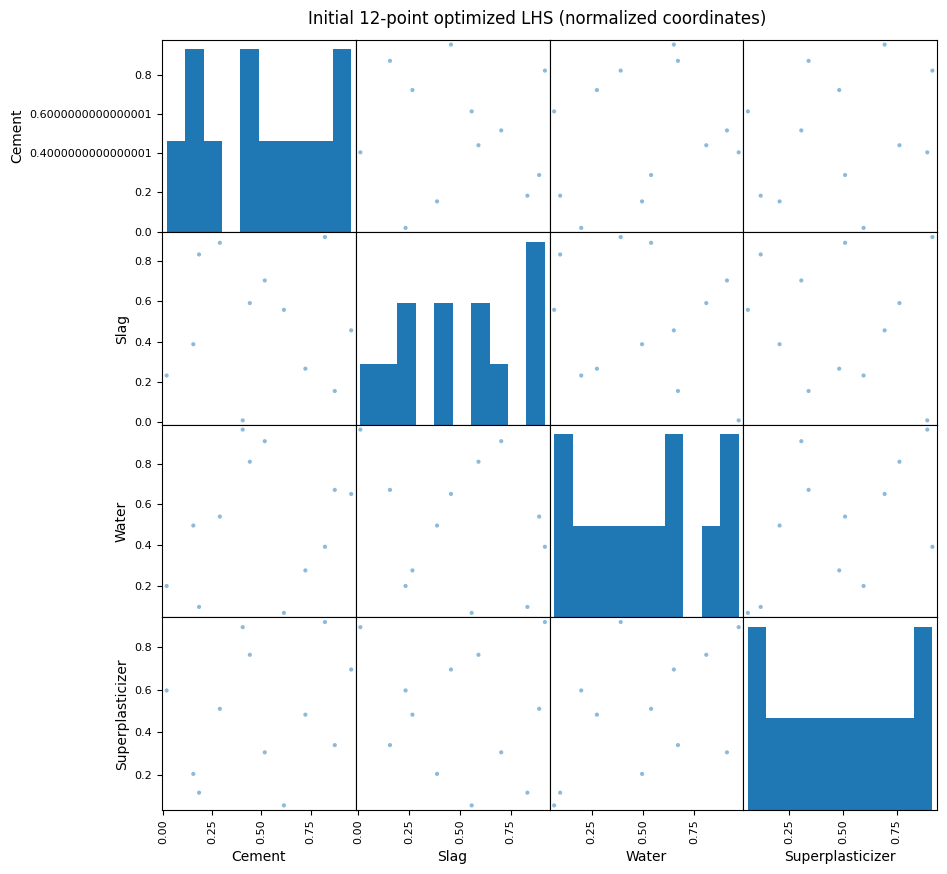

In [ ]:
scatter_matrix(pd.DataFrame(U0,columns=design_vars),
               figsize=(10,10), diagonal="hist")
plt.suptitle("Initial 12-point optimized LHS (normalized coordinates)",y=.91)
plt.show()


# 4. Initial surrogate models

We compare a quadratic response surface with a Gaussian Process.

A quadratic model has the general form

$
\hat f(\mathbf{x})=\beta_0+\sum_i\beta_i x_i+
\sum_i\beta_{ii}x_i^2+\sum_{i<j}\beta_{ij}x_ix_j.
$

A GP provides both a predictive mean and uncertainty,

$
\mu(\mathbf{x}),\qquad \sigma(\mathbf{x}),
$

making it particularly useful for sequential sampling.


In [ ]:
def build_quadratic():
    return make_pipeline(StandardScaler(),
                         PolynomialFeatures(2,include_bias=False),
                         LinearRegression())

def build_gp():
    kernel = (ConstantKernel(1.0,(1e-2,1e2)) *
              Matern(length_scale=np.ones(4),
                     length_scale_bounds=(.05,20),nu=2.5)
              + WhiteKernel(1e-4,(1e-8,1e-1)))
    return make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(kernel=kernel,normalize_y=True,
            n_restarts_optimizer=2,random_state=RANDOM_STATE)
    )

quadratic, gp = build_quadratic(), build_gp()
quadratic.fit(X0,y0)
gp.fit(X0,y0)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('gaussianprocessregressor',
                 GaussianProcessRegressor(kernel=1**2 * Matern(length_scale=[1, 1, 1, 1], nu=2.5) + WhiteKernel(noise_level=0.0001),
                                          n_restarts_optimizer=2,
                                          normalize_y=True,
                                          random_state=640))])

# 5. Independent validation

A 512-point Sobol sample is evaluated with the reference model. These locations are used only for assessment, never for surrogate fitting.


In [ ]:
sampler_val = qmc.Sobol(d=4,scramble=True,seed=2026)
U_val = sampler_val.random_base2(m=9)
X_val = qmc.scale(U_val,lower,upper)
y_val = expensive_evaluation(X_val)

def metrics(model):
    p = model.predict(X_val)
    return {"RMSE":mean_squared_error(y_val,p)**0.5,
            "R2":r2_score(y_val,p),
            "Max absolute error":np.max(np.abs(y_val-p))}

display(pd.DataFrame({
    "Quadratic":metrics(quadratic),
    "Gaussian Process":metrics(gp)
}).T.round(4))


,RMSE,R2,Max absolute error
Quadratic,5.8786,0.6595,18.0375
Gaussian Process,4.7664,0.7761,14.8895


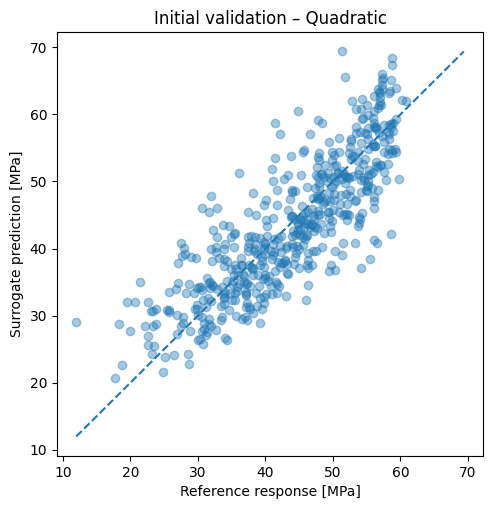

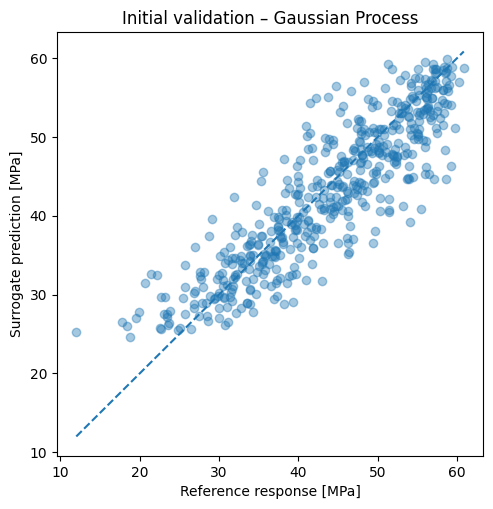

In [ ]:
for name,model in {"Quadratic":quadratic,"Gaussian Process":gp}.items():
    p=model.predict(X_val)
    fig,ax=plt.subplots(figsize=(5.5,5.5))
    ax.scatter(y_val,p,alpha=.4)
    lo=min(y_val.min(),p.min()); hi=max(y_val.max(),p.max())
    ax.plot([lo,hi],[lo,hi],"--")
    ax.set(xlabel="Reference response [MPa]",
           ylabel="Surrogate prediction [MPa]",
           title=f"Initial validation – {name}")
    plt.show()


### Questions 5.1–5.3
1. Which initial surrogate has lower validation RMSE?
2. Why can a model with acceptable global RMSE still recommend a poor optimum?
3. What additional capability does the GP provide that is useful for sequential DOE?

**Write your answers here.**


# 6. Expected Improvement

If we maximize only the GP mean, we exploit current knowledge. Sequential optimization should also consider uncertain locations.

For maximization, with best observed response $f_{best}$,

$
Z=\frac{\mu-f_{best}-\xi}{\sigma},
$

$
EI=(\mu-f_{best}-\xi)\Phi(Z)+\sigma\phi(Z).
$

A location can therefore have large EI because it has:
- high predicted performance (**exploitation**),
- high uncertainty (**exploration**),
- or both.


In [ ]:
def gp_mean_std(pipe,X):
    scaler=pipe.named_steps["standardscaler"]
    gpr=pipe.named_steps["gaussianprocessregressor"]
    return gpr.predict(scaler.transform(np.atleast_2d(X)),return_std=True)

def expected_improvement(pipe,X,y_obs,xi=.01):
    mu,sigma=gp_mean_std(pipe,X)
    imp=mu-np.max(y_obs)-xi
    Z=np.divide(imp,sigma,out=np.zeros_like(imp),where=sigma>1e-12)
    ei=imp*norm.cdf(Z)+sigma*norm.pdf(Z)
    ei[sigma<=1e-12]=0
    return ei,mu,sigma

candidate_sampler=qmc.Sobol(d=4,scramble=True,seed=1001)
U_candidates=candidate_sampler.random_base2(m=12) # 4096 candidates
X_candidates=qmc.scale(U_candidates,lower,upper)
print("Candidate locations:",len(X_candidates))


Candidate locations: 4096


# 7. Sequential surrogate improvement and optimization

Starting from the 12-point optimal LHS, add **12 new evaluations one at a time**.

At every iteration:

1. fit/update the GP;
2. calculate validation RMSE;
3. determine the current GP-predicted optimum;
4. calculate Expected Improvement;
5. choose the highest-EI unsampled location;
6. purchase one new expensive response;
7. append it to the DOE.

Total final cost:

$
12+12=24\text{ expensive evaluations}.
$


In [ ]:
N_SEQUENTIAL=12
X_seq,y_seq=X0.copy(),y0.copy()
history=[]

for iteration in range(N_SEQUENTIAL+1):
    current=build_gp()
    current.fit(X_seq,y_seq)

    vp=current.predict(X_val)
    rmse=mean_squared_error(y_val,vp)**0.5
    r2=r2_score(y_val,vp)

    cm=current.predict(X_candidates)
    j=np.argmax(cm)
    pred_opt=cm[j]
    ref_at_opt=expensive_evaluation(X_candidates[j])[0]

    history.append({
        "Evaluations":len(y_seq),
        "Best observed [MPa]":y_seq.max(),
        "Validation RMSE [MPa]":rmse,
        "Validation R2":r2,
        "Predicted optimum [MPa]":pred_opt,
        "Reference at predicted optimum [MPa]":ref_at_opt
    })

    if iteration==N_SEQUENTIAL:
        final_gp=current
        break

    ei,mu,sigma=expected_improvement(current,X_candidates,y_seq,xi=.01)

    # Prevent nearly duplicate acquisitions
    existing_U=(X_seq-lower)/(upper-lower)
    min_dist=np.min(np.linalg.norm(
        U_candidates[:,None,:]-existing_U[None,:,:],axis=2),axis=1)
    ei[min_dist<.015]=-np.inf

    nxt=np.argmax(ei)
    X_seq=np.vstack([X_seq,X_candidates[nxt]])
    y_seq=np.append(y_seq,expensive_evaluation(X_candidates[nxt])[0])

history_df=pd.DataFrame(history)
display(history_df.round(4))


,Evaluations,Best observed [MPa],Validation RMSE [MPa],Validation R2,Predicted optimum [MPa],Reference at predicted optimum [MPa]
0,12,57.5407,4.7664,0.7761,60.1189,57.6118
1,13,59.8656,4.7705,0.7758,59.9982,57.6118
2,14,59.8656,4.4280,0.8068,59.8656,59.8656
3,15,59.8656,4.5007,0.8004,59.9072,55.9809
4,16,59.8656,4.4764,0.8026,58.9065,59.8656
5,17,59.8656,4.3409,0.8143,58.7982,59.8656
6,18,59.8656,4.4117,0.8082,59.8656,59.8656
7,19,59.8656,4.3430,0.8141,59.8656,59.8656
8,20,60.0632,4.2743,0.8200,60.0632,60.0632
9,21,60.0632,4.3207,0.8161,59.5201,59.8656


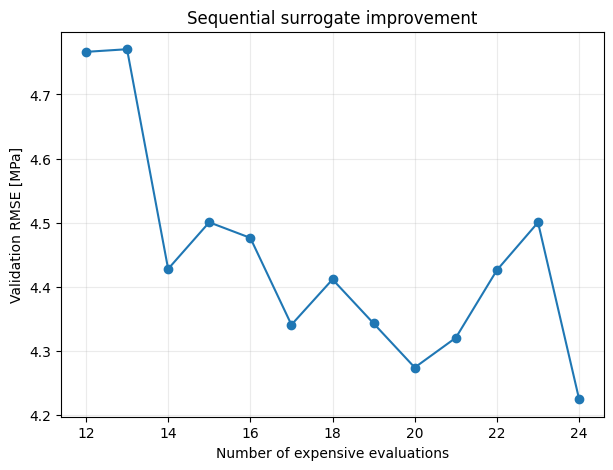

In [ ]:
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(history_df.Evaluations,
        history_df["Validation RMSE [MPa]"],marker="o")
ax.set(xlabel="Number of expensive evaluations",
       ylabel="Validation RMSE [MPa]",
       title="Sequential surrogate improvement")
ax.grid(alpha=.25)
plt.show()


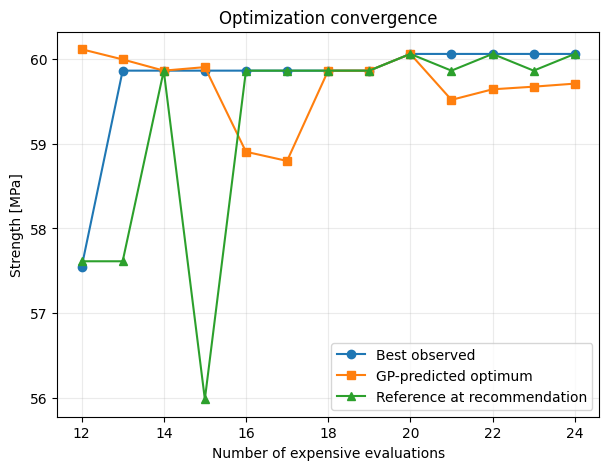

In [ ]:
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(history_df.Evaluations,history_df["Best observed [MPa]"],
        marker="o",label="Best observed")
ax.plot(history_df.Evaluations,history_df["Predicted optimum [MPa]"],
        marker="s",label="GP-predicted optimum")
ax.plot(history_df.Evaluations,
        history_df["Reference at predicted optimum [MPa]"],
        marker="^",label="Reference at recommendation")
ax.set(xlabel="Number of expensive evaluations",
       ylabel="Strength [MPa]",title="Optimization convergence")
ax.legend(); ax.grid(alpha=.25); plt.show()


### Questions 7.1–7.5
1. Did RMSE decrease monotonically? Should it necessarily?
2. When did the best observed response improve?
3. Did the discrepancy between predicted and reference optimum generally improve?
4. Why does EI sometimes select a point that does not have the highest predicted mean?
5. Why are global surrogate improvement and optimum-finding related but different objectives?

**Write your answers here.**


# 8. Final optimized design and high-fidelity verification


In [ ]:
final_mu,final_sigma=gp_mean_std(final_gp,X_candidates)
j=np.argmax(final_mu)
x_star=X_candidates[j]
predicted=final_mu[j]
uncertainty=final_sigma[j]
verified=expensive_evaluation(x_star)[0]

display(pd.DataFrame({
    "Variable":design_vars,
    "Recommended value":x_star,
    "Lower bound":lower,
    "Upper bound":upper
}).round(3))

print(f"GP prediction:       {predicted:.3f} MPa")
print(f"GP predictive std.:  {uncertainty:.3f} MPa")
print(f"Reference response:  {verified:.3f} MPa")
print(f"Best sampled value:  {y_seq.max():.3f} MPa")


,Variable,Recommended value,Lower bound,Upper bound
0,Cement,474.274,143.745,480.000
1,Slag,165.484,0.000,236.000
2,Water,148.475,146.140,228.000
3,Superplasticizer,10.343,0.000,16.055


GP prediction:       59.712 MPa
GP predictive std.:  0.984 MPa
Reference response:  60.063 MPa
Best sampled value:  60.063 MPa


### Questions 8.1–8.4
1. Are any recommended variables near their bounds?
2. Is predictive uncertainty small relative to the predicted strength?
3. Does verification support the recommendation?
4. Why should this not be described as a proven global optimum?

**Write your answers here.**


# 9. Equal-budget comparison: sequential EI versus one-shot optimal LHS

Sequential sampling should not be compared against only the original 12-point DOE. That would give it twice the evaluation budget.

Instead, construct a **24-point one-shot optimized LHS**, fit a GP once, and compare both strategies at exactly 24 expensive evaluations.

This distinguishes two different philosophies:

### One-shot DOE
Spend the entire budget maximizing global space coverage before observing responses.

### Sequential DOE
Spend an initial budget on coverage, then let observed responses and uncertainty guide later evaluations.


In [ ]:
U_one,score_one=optimized_lhs(24,4,n_candidates=500,seed=2027)
X_one=qmc.scale(U_one,lower,upper)
y_one=expensive_evaluation(X_one)

gp_one=build_gp()
gp_one.fit(X_one,y_one)
one_val=gp_one.predict(X_val)
one_rmse=mean_squared_error(y_val,one_val)**0.5
one_r2=r2_score(y_val,one_val)

one_mu=gp_one.predict(X_candidates)
jo=np.argmax(one_mu)
one_pred=one_mu[jo]
one_verified=expensive_evaluation(X_candidates[jo])[0]

seq_val=final_gp.predict(X_val)
seq_rmse=mean_squared_error(y_val,seq_val)**0.5
seq_r2=r2_score(y_val,seq_val)

comparison=pd.DataFrame({
    "Sequential EI":[24,seq_rmse,seq_r2,y_seq.max(),predicted,verified],
    "One-shot optimal LHS":[24,one_rmse,one_r2,y_one.max(),one_pred,one_verified]
},index=[
    "Expensive evaluations","Validation RMSE [MPa]","Validation R2",
    "Best observed [MPa]","Predicted optimum [MPa]",
    "Reference at recommended design [MPa]"
])
display(comparison.round(4))


,Sequential EI,One-shot optimal LHS
Expensive evaluations,24.0000,24.0000
Validation RMSE [MPa],4.2249,3.6556
Validation R2,0.8241,0.8683
Best observed [MPa],60.0632,59.3619
Predicted optimum [MPa],59.7122,63.4162
Reference at recommended design [MPa],60.0632,59.8258


### Questions 9.1–9.4
1. Which strategy achieved better global prediction accuracy?
2. Which strategy recommended the better design?
3. If one strategy has lower RMSE while the other finds a better optimum, is that contradictory?
4. When would you prefer a one-shot DOE instead of sequential optimization?

**Write your answers here.**


# 10. Optional advanced investigation: exploration parameter

Repeat the sequential experiment for several Expected Improvement exploration parameters,

$
\xi=0,\quad 0.05,\quad 0.20.
$

Compare:
- validation RMSE;
- best sampled response;
- verified final recommendation;
- spatial distribution of acquired points.

### Question 10.1
Before running the experiment, predict how increasing $\xi$ should alter exploration versus exploitation. Then compare your prediction with the results.


# 11. Extension to constrained or multiobjective design

A realistic formulation might maximize strength while imposing cost and mixture constraints:

$$
\max_{\mathbf{x}}\ f_{\text{strength}}(\mathbf{x})
$$

subject to

$$
C(\mathbf{x})\le C_{\max},
\qquad
g_j(\mathbf{x})\le0.
$$

Alternatively,

$$
\max f_{\text{strength}}(\mathbf{x}),
\qquad
\min f_{\text{cost}}(\mathbf{x})
$$

creates a multiobjective problem and leads to Pareto-optimal design.

### Optional challenge
Define a hypothetical material-cost function and extend the exercise to strength-versus-cost optimization.


# Final reflection

Answer concisely.

1. What does optimal/maximin LHS improve relative to an arbitrary LHS?
2. Why is an initial space-filling DOE still needed before sequential optimization?
3. What does GP predictive uncertainty mean here?
4. Explain Expected Improvement without using an equation.
5. How does EI balance exploration and exploitation?
6. Why must a surrogate optimum be verified?
7. Why is global prediction accuracy not identical to optimization performance?
8. What did the equal-budget comparison reveal?
9. If each evaluation cost $25,000, what stopping criterion would you use?
10. Give one mechanical-engineering application for this workflow.


# Submission checklist

Your completed notebook should contain:

- dataset inspection and design-domain definition;
- 12-point maximin optimized LHS;
- initial quadratic and GP surrogates;
- independent validation and parity plots;
- interpretation of GP uncertainty;
- Expected Improvement formulation;
- 12 sequential acquisitions;
- surrogate-error convergence;
- optimum convergence;
- final design and high-fidelity verification;
- equal-budget comparison against a 24-point one-shot optimal LHS;
- engineering critique;
- final reflection.

## Central lesson

$
\boxed{
\text{Optimal initial DOE}
\rightarrow
\text{Learn}
\rightarrow
\text{Quantify uncertainty}
\rightarrow
\text{Acquire}
\rightarrow
\text{Update}
\rightarrow
\text{Optimize}
}
$

In sequential surrogate-based design, the DOE, surrogate, uncertainty model, and optimizer form a single iterative decision process.
